# Continuous vs. Discrete Spectra

> *A plot of EM intensity per unit wavelength can be continuous or discrete. Which option gives
> correct examples of each?*

| source | spectrum | why |
|---|---|---|
| **blackbody** (hot dense matter) | **continuous** | trillions of interacting charges: every wavelength, shaped by T alone |
| **gas discharge tube** (isolated atoms) | **discrete** | electrons jump between fixed energy levels |
| x-ray tube | **both** | continuous bremsstrahlung *plus* discrete characteristic lines |
| cathode rays | **not EM at all** | they are electrons (Thomson, 1897) |

**Answer: "blackbody is continuous, gas discharge tube is discrete."** Below, each row of
the table is derived in SymPy and checked numerically. Module:
[`dgs/spectra_continuous_discrete.py`](../dgs/spectra_continuous_discrete.py)

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import sympy as sp
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Math
sp.init_printing()
from dgs.spectra_continuous_discrete import (
    bose_integral_by_series, bose_integral_numeric, stefan_boltzmann_symbolic, sigma_numeric,
    planck_lambda, hydrogen_level_eV, hydrogen_line_nm, series_limit_symbolic,
    duane_hunt_cutoff_nm, kramers_spectrum, moseley_kalpha_keV, OPTIONS, check_option,
)

# 1. Continuous: the blackbody, and what "continuous" lets you do

A continuous spectrum can be **integrated**. Integrating Planck's law over all wavelengths gives
the total power, the Stefan–Boltzmann law $P/A = \sigma T^4$. The integral that appears,
$\int_0^\infty \frac{x^3}{e^x - 1}dx$, **cannot be done by SymPy directly**. So do it the Calc 2 way:
expand $\frac{1}{e^x-1} = \sum_{n\ge1}e^{-nx}$ (a geometric series), integrate term by term, then sum:

In [2]:
x = sp.Symbol("x", positive=True)
print("SymPy directly:", sp.integrate(x**3/(sp.exp(x) - 1), (x, 0, sp.oo)))
term, total = bose_integral_by_series()
display(Math(r"\int_0^\infty x^3 e^{-nx}\,dx = " + sp.latex(term) + r",\qquad \sum_{n=1}^\infty " + sp.latex(term) + " = " + sp.latex(total)))
print(f"numeric quad = {bose_integral_numeric():.12f}    π⁴/15 = {float(total):.12f}")
I, sigma = stefan_boltzmann_symbolic()
display(Math(r"\sigma = " + sp.latex(sigma) + f" = {sigma_numeric():.6e}" + r"\ \text{W m}^{-2}\text{K}^{-4}"))

SymPy directly: Integral(x**3/(exp(x) - 1), (x, 0, oo))


<IPython.core.display.Math object>

numeric quad = 6.493939402267    π⁴/15 = 6.493939402267


<IPython.core.display.Math object>

That's exactly the CODATA value of σ, built from $h$, $c$ and $k$ alone. Only a *continuous*
spectrum has a smooth integral like this.

# 2. Discrete: hydrogen in a discharge tube

The electron's energy is restricted to $E_n = -13.6\ \text{eV}/n^2$. A photon carries away exactly
the difference between two levels, so only certain wavelengths appear:
$\frac1\lambda = R\left(\frac1{n_l^2} - \frac1{n_u^2}\right)$. As $n_u\to\infty$ the lines crowd together at the
**series limit**, a SymPy limit:

In [3]:
lim, lam_expr = series_limit_symbolic(2)
display(Math(r"\lambda(n_u) = " + sp.latex(lam_expr) + r",\qquad \lim_{n_u\to\infty}\lambda = " + sp.latex(lim) + r" = 364.5\ \text{nm}"))
rows = [{"n_upper": n, "E_n (eV)": hydrogen_level_eV(n), "Balmer line (nm)": hydrogen_line_nm(n, 2)} for n in range(3, 9)]
pd.DataFrame(rows).round(3)

<IPython.core.display.Math object>

,n_upper,E_n (eV),Balmer line (nm)
0,3,-1.512,656.112
1,4,-0.850,486.009
2,5,-0.544,433.937
3,6,-0.378,410.070
4,7,-0.278,396.907
5,8,-0.213,388.807


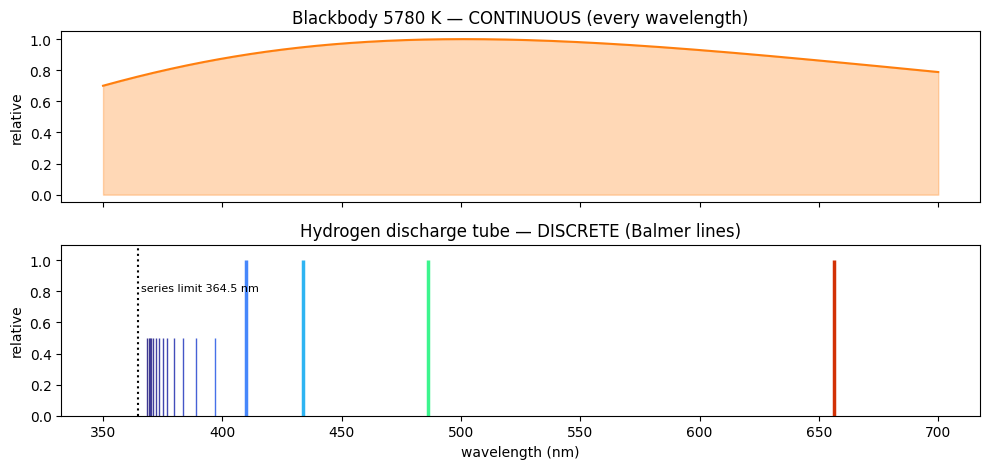

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(10, 4.8), sharex=True)
lam = np.linspace(350, 700, 1000); B = planck_lambda(lam, 5780)
axes[0].fill_between(lam, B/B.max(), color="C1", alpha=0.3); axes[0].plot(lam, B/B.max(), "C1")
axes[0].set(ylabel="relative", title="Blackbody 5780 K — CONTINUOUS (every wavelength)")
for n in range(3, 20):
    l = hydrogen_line_nm(n, 2)
    axes[1].vlines(l, 0, 1 if n < 7 else 0.5, color=plt.cm.turbo((l - 350)/350), lw=2.5 if n < 7 else 1)
axes[1].axvline(364.5, color="k", ls=":"); axes[1].text(366, 0.8, "series limit 364.5 nm", fontsize=8)
axes[1].set(ylim=(0, 1.1), xlabel="wavelength (nm)", ylabel="relative", title="Hydrogen discharge tube — DISCRETE (Balmer lines)")
plt.tight_layout(); plt.show()

# 3. The trap: an x-ray tube is *both*

Electrons accelerated through voltage $V$ slam into a metal target.

- **Bremsstrahlung** ("braking radiation") is **continuous**, with a hard short-wavelength
  cutoff where one electron's whole energy becomes one photon: $\lambda_\min = hc/eV$ (Duane–Hunt).
- **Characteristic lines** are **discrete**: the electron knocks out an inner-shell electron and
  an outer one drops in. Moseley's law gives $E_{K\alpha} \approx \tfrac34(13.6\ \text{eV})(Z-1)^2$.

So "x rays are discrete" and "x rays are continuous" are each only half true. That's why
the two x-ray options aren't the *accurate* answer, even setting aside the cathode-ray error.

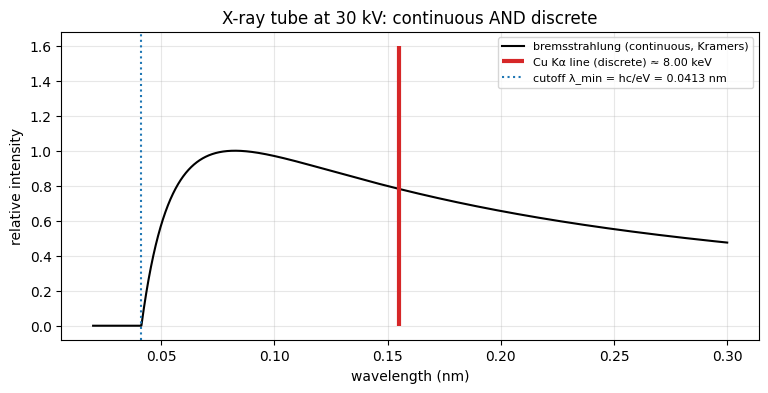

Cu Kα from Moseley: 8.00 keV (measured ≈ 8.05 keV);  λ = 0.1550 nm


In [5]:
V, Z = 30e3, 29                                  # 30 kV tube, copper target
lam = np.linspace(0.02, 0.3, 4000); I = kramers_spectrum(lam, V)
E_ka = moseley_kalpha_keV(Z); lam_ka = 1.23984 / E_ka
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(lam, I/I.max(), "k", label="bremsstrahlung (continuous, Kramers)")
ax.vlines(lam_ka, 0, 1.6, color="C3", lw=3, label=f"Cu Kα line (discrete) ≈ {E_ka:.2f} keV")
ax.axvline(duane_hunt_cutoff_nm(V), color="C0", ls=":", label=f"cutoff λ_min = hc/eV = {duane_hunt_cutoff_nm(V):.4f} nm")
ax.set(xlabel="wavelength (nm)", ylabel="relative intensity", title="X-ray tube at 30 kV: continuous AND discrete")
ax.legend(fontsize=8); ax.grid(alpha=0.3); plt.show()
print(f"Cu Kα from Moseley: {E_ka:.2f} keV (measured ≈ 8.05 keV);  λ = {lam_ka:.4f} nm")

# 4. Loop over the answer options

In [6]:
for i, opt in enumerate(OPTIONS, 1):
    ok, why = check_option(opt)
    print(f"{'✓' if ok else '✗'} {i}. {opt[0]} {opt[1]}, {opt[2]} {opt[3]}")
    for w in why:
        print(f"      – {w}")

✗ 1. cathode rays continuous, x rays discrete
      – cathode rays are electrons, not EM radiation
      – x rays is BOTH continuous and discrete (only half true)
✗ 2. x rays continuous, cathode rays discrete
      – x rays is BOTH continuous and discrete (only half true)
      – cathode rays are electrons, not EM radiation
✗ 3. blackbody discrete, gas discharge tube continuous
      – blackbody is continuous, not discrete
      – gas discharge tube is discrete, not continuous
✓ 4. blackbody continuous, gas discharge tube discrete


## Exercises
1. Use `planck_lambda` and `np.trapezoid` to check $\pi\int B_\lambda\,d\lambda = \sigma T^4$ for $T = 3000$ K.
2. Lyman series ($n_l = 1$): find its series limit with `series_limit_symbolic(1)`. Is it visible?
3. Raise the tube voltage to 60 kV. Where does $\lambda_\min$ move, and does the Cu Kα line move?
4. Why does a *dense* gas (or a star's interior) glow with a continuous spectrum, while a *thin* gas shows lines?